# 02 - Model Development and Experiment Tracking

Models are selected, tuned and compared on the cleaned heart disease data, and
the runs are recorded in MLflow. The steps common to all models are functions
in `src/`.

1. Data split
2. Evaluation method
3. Model selection
4. `ca` as categorical or numerical
5. Logistic Regression
6. Random Forest
7. Gradient Boosting
8. XGBoost
9. Comparison of the models
10. Selected model
11. Evaluation on the test set

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
from sklearn.base import clone
from sklearn.linear_model import LogisticRegression

# project root, one level above notebooks/
ROOT = Path.cwd().parent
sys.path.insert(0, str(ROOT))

from src.data_prep import CATEGORICAL, NUMERIC
from src.evaluation import (
    METRICS,
    RANDOM_STATE,
    ROC_AUC_GAP,
    ROC_AUC_GATE,
    build_metrics_table,
    compute_metrics,
    create_cv_folds,
    cross_val_probabilities,
    passes_quality_gate,
    plot_confusion_matrix,
    plot_roc_curve,
    readable_metrics,
    run_grid_search,
    select_best_model,
    split_data,
)
from src.models import MODELS
from src.preprocessing import make_pipeline
from src.tracking import (
    load_model_results,
    load_trained_model,
    log_model_runs,
    log_test_results,
)

pd.set_option("display.width", 200)

## 1. Data split

80% training and 20% test, stratified, with a fixed seed. The test set is
used only once, at the end, for the selected model.

In [2]:
X_train, X_test, y_train, y_test = split_data()

split = pd.DataFrame({
    "patients": [len(y_train), len(y_test)],
    "with disease": [int(y_train.sum()), int(y_test.sum())],
    "disease share (%)": [round(y_train.mean() * 100, 1), round(y_test.mean() * 100, 1)],
}, index=["training", "test"])
split

,patients,with disease,disease share (%)
training,242,111,45.9
test,61,28,45.9


The objective of the experiment is to select the best model. It has to beat
these scores, which can be got without learning anything from the data:

- Accuracy: about 54%. A model that predicts "no disease" for every patient
  gets this, because 54% of the patients do not have the disease.
- ROC-AUC: 0.5. Random guessing gives this.

## 2. Evaluation method

- 10-fold stratified cross-validation on the training patients.
- Metrics: accuracy, precision, recall, F1 and ROC-AUC, as mean and standard
  deviation over the folds.
- Grid search for tuning. The best setting of a model is the one with the
  highest mean ROC-AUC. If two settings are equal, the simpler one is taken.
- All runs are recorded in MLflow.

In [3]:
folds = create_cv_folds()
folds

StratifiedKFold(n_splits=10, random_state=42, shuffle=True)

## 3. Model selection

Points considered while choosing the models:

- Only 242 patients are available for training, so models that need a lot of
  data were left out.
- Each prediction has to come with its confidence, so the model must be able
  to give a probability.
- The EDA showed non-linear patterns, for example for `ca` and `slope`.
- The outliers were kept in the data.
- It should be possible to explain a prediction.

Models selected:

- Logistic Regression: simple and easy to explain. Used as the reference
  model.
- Random Forest: handles non-linear patterns and outliers.
- Gradient Boosting: tree-based and usually accurate on table data, but can
  overfit small data.
- XGBoost: a widely used library for gradient boosting, with more controls
  against overfitting.

Support Vector Machine was considered but not used. It does not give a
probability directly, and its predictions are the hardest to explain.

## 4. `ca` as categorical or numerical

`ca` is a count from 0 to 3. In the EDA it was treated as categorical, because
the disease share did not rise in equal steps with the count (notebook 01,
section 11). Both forms are tried here on the reference model with its default
setting (`C` = 1), on the same folds.

In [4]:
model_name = "Logistic Regression"
default_grid = {"model__C": [1.0]}

# ca moved from the categorical list to the numerical list
numeric_with_ca = NUMERIC + ["ca"]
categorical_without_ca = CATEGORICAL.copy()
categorical_without_ca.remove("ca")

ca_pipelines = {
    "categorical": make_pipeline(LogisticRegression(random_state=RANDOM_STATE)),
    "numerical": make_pipeline(
        LogisticRegression(random_state=RANDOM_STATE),
        numeric=numeric_with_ca,
        categorical=categorical_without_ca,
    ),
}

ca_tables = []
for ca_form, ca_pipeline in ca_pipelines.items():
    ca_search = run_grid_search(ca_pipeline, default_grid, X_train, y_train, folds)
    ca_table = build_metrics_table(ca_search)
    log_model_runs(
        f"{model_name} (ca {ca_form})", ca_pipeline, ca_search, ca_table,
        X_train, y_train, folds, tags={"experiment": "ca form"},
    )
    ca_table.insert(0, "ca", ca_form)
    ca_tables.append(ca_table)

readable_metrics(pd.concat(ca_tables, ignore_index=True))

Logged to MLflow: Logistic Regression (ca categorical), 1 combinations.
Logged to MLflow: Logistic Regression (ca numerical), 1 combinations.


,ca,C,accuracy,precision,recall,f1,roc_auc
0,categorical,1.0,0.847 ± 0.063,0.879 ± 0.100,0.793 ± 0.107,0.826 ± 0.066,0.904 ± 0.052
1,numerical,1.0,0.831 ± 0.055,0.856 ± 0.091,0.776 ± 0.106,0.807 ± 0.061,0.907 ± 0.050


Observations

The two forms give almost the same result. ROC-AUC is 0.904 with `ca` as
categorical and 0.907 as numerical. This gap is much smaller than the standard
deviation across the folds (about 0.05). The other four metrics are slightly
higher for the categorical form. As there is no clear difference, `ca` is kept
as categorical, as decided in the EDA.

## 5. Logistic Regression

Reference model. The default L2 penalty is used and its strength `C` is tuned.
A smaller `C` gives a simpler model. The default value, `C` = 1, is one of the
values tried.

In [5]:
model_name = "Logistic Regression"

# the model and its grid are defined in src/models.py
model, grid = MODELS[model_name]
pipeline = make_pipeline(model)

# "model__C" is the setting C of the pipeline step named "model"
for setting, values in grid.items():
    print(setting, "=", values)

model__C = [0.01, 0.1, 1, 10]


In [6]:
search = run_grid_search(pipeline, grid, X_train, y_train, folds)
metrics_table = build_metrics_table(search)

print("Combinations tried:", len(metrics_table))
print("Best setting by ROC-AUC:", search.best_params_)

Combinations tried: 4
Best setting by ROC-AUC: {'model__C': 0.1}


In [7]:
# recorded in MLflow: a parent run for the model, a child run for each
# combination, and the trained model of the best setting
log_model_runs(model_name, pipeline, search, metrics_table, X_train, y_train, folds)

Logged to MLflow: Logistic Regression, 4 combinations.


In [8]:
# mean ± std over the 10 folds
readable_metrics(metrics_table)

,C,accuracy,precision,recall,f1,roc_auc
0,0.01,0.806 ± 0.069,0.880 ± 0.124,0.694 ± 0.082,0.768 ± 0.069,0.888 ± 0.059
1,0.10,0.831 ± 0.050,0.852 ± 0.097,0.784 ± 0.092,0.810 ± 0.049,0.905 ± 0.048
2,1.00,0.847 ± 0.063,0.879 ± 0.100,0.793 ± 0.107,0.826 ± 0.066,0.904 ± 0.052
3,10.00,0.839 ± 0.063,0.860 ± 0.097,0.794 ± 0.112,0.818 ± 0.067,0.902 ± 0.052


In [9]:
# default setting (C = 1) against the best setting
default_row = metrics_table[metrics_table["C"] == 1]
best_row = metrics_table.loc[[search.best_index_]]

comparison = pd.concat([default_row, best_row])
comparison.insert(0, "setting", ["default", "best"])
readable_metrics(comparison)

,setting,C,accuracy,precision,recall,f1,roc_auc
2,default,1.0,0.847 ± 0.063,0.879 ± 0.100,0.793 ± 0.107,0.826 ± 0.066,0.904 ± 0.052
1,best,0.1,0.831 ± 0.050,0.852 ± 0.097,0.784 ± 0.092,0.810 ± 0.049,0.905 ± 0.048


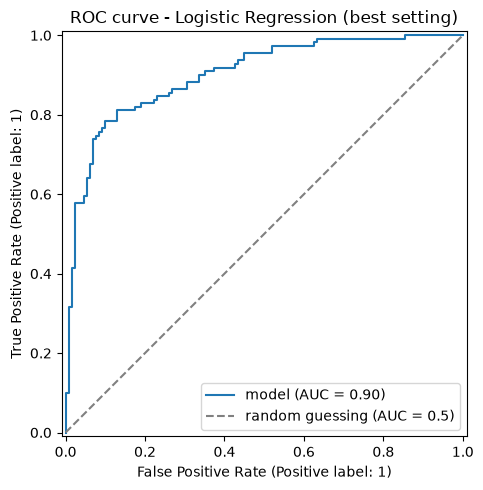

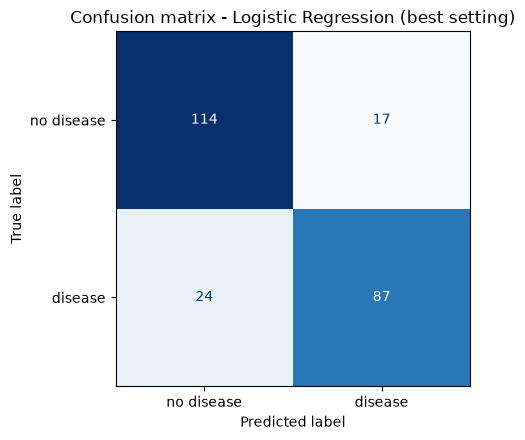

In [10]:
# plots for the best setting, from the cross-validation predictions
best_pipeline = clone(pipeline).set_params(**search.best_params_)
probability = cross_val_probabilities(best_pipeline, X_train, y_train, folds)

plot_roc_curve(y_train, probability, f"ROC curve - {model_name} (best setting)")
plot_confusion_matrix(y_train, probability, f"Confusion matrix - {model_name} (best setting)")
plt.show()

Observations

- The best setting is `C` = 0.1, with a mean ROC-AUC of 0.905.
- ROC-AUC stays between 0.902 and 0.905 for `C` = 0.1, 1 and 10, so the model
  is not sensitive to `C` in this range.
- Tuning gave no real gain over the default setting (0.905 against 0.904).

Recall is 0.784 at the best setting, so about 22% of the patients with disease
are missed.

## 6. Random Forest

An average of many decision trees. The size of each tree (`max_depth` and
`min_samples_leaf`) and the number of trees (`n_estimators`) are tuned. The
default setting (no depth limit, 1 patient in a leaf, 100 trees) is one of the
combinations tried.

In [11]:
model_name = "Random Forest"

model, grid = MODELS[model_name]
pipeline = make_pipeline(model)

# each setting is written from the simplest value to the most complex
for setting, values in grid.items():
    print(setting, "=", values)

model__max_depth = [3, 5, None]
model__min_samples_leaf = [5, 3, 1]
model__n_estimators = [100, 300]


In [12]:
search = run_grid_search(pipeline, grid, X_train, y_train, folds)
metrics_table = build_metrics_table(search)

print("Combinations tried:", len(metrics_table))
print("Best setting by ROC-AUC:", search.best_params_)

Combinations tried: 18
Best setting by ROC-AUC: {'model__max_depth': 5, 'model__min_samples_leaf': 3, 'model__n_estimators': 300}


In [13]:
# recorded in MLflow: a parent run for the model, a child run for each
# combination, and the trained model of the best setting
log_model_runs(model_name, pipeline, search, metrics_table, X_train, y_train, folds)

Logged to MLflow: Random Forest, 18 combinations.


In [14]:
# mean ± std over the 10 folds
readable_metrics(metrics_table)

,max_depth,min_samples_leaf,n_estimators,accuracy,precision,recall,f1,roc_auc
0,3,5,100,0.809 ± 0.044,0.831 ± 0.102,0.765 ± 0.117,0.784 ± 0.047,0.900 ± 0.041
1,3,5,300,0.814 ± 0.051,0.843 ± 0.115,0.765 ± 0.117,0.789 ± 0.052,0.904 ± 0.041
2,3,3,100,0.810 ± 0.043,0.833 ± 0.105,0.765 ± 0.117,0.785 ± 0.044,0.899 ± 0.041
3,3,3,300,0.814 ± 0.051,0.843 ± 0.115,0.765 ± 0.117,0.789 ± 0.052,0.904 ± 0.035
4,3,1,100,0.801 ± 0.053,0.834 ± 0.110,0.747 ± 0.135,0.772 ± 0.057,0.900 ± 0.039
5,3,1,300,0.818 ± 0.048,0.850 ± 0.110,0.765 ± 0.117,0.792 ± 0.048,0.899 ± 0.039
6,5,5,100,0.797 ± 0.064,0.820 ± 0.123,0.756 ± 0.116,0.774 ± 0.057,0.894 ± 0.042
7,5,5,300,0.805 ± 0.060,0.824 ± 0.117,0.765 ± 0.110,0.783 ± 0.059,0.902 ± 0.044
8,5,3,100,0.805 ± 0.057,0.831 ± 0.118,0.765 ± 0.117,0.783 ± 0.052,0.900 ± 0.043
9,5,3,300,0.810 ± 0.050,0.829 ± 0.115,0.774 ± 0.110,0.788 ± 0.048,0.905 ± 0.040


In [15]:
# default setting (no depth limit, 1 patient in a leaf, 100 trees) against
# the best setting
default_row = metrics_table[
    (metrics_table["max_depth"] == "None")
    & (metrics_table["min_samples_leaf"] == 1)
    & (metrics_table["n_estimators"] == 100)
]
best_row = metrics_table.loc[[search.best_index_]]

comparison = pd.concat([default_row, best_row])
comparison.insert(0, "setting", ["default", "best"])
readable_metrics(comparison)

,setting,max_depth,min_samples_leaf,n_estimators,accuracy,precision,recall,f1,roc_auc
16,default,None,1,100,0.793 ± 0.068,0.809 ± 0.123,0.756 ± 0.093,0.772 ± 0.062,0.889 ± 0.045
9,best,5,3,300,0.810 ± 0.050,0.829 ± 0.115,0.774 ± 0.110,0.788 ± 0.048,0.905 ± 0.040


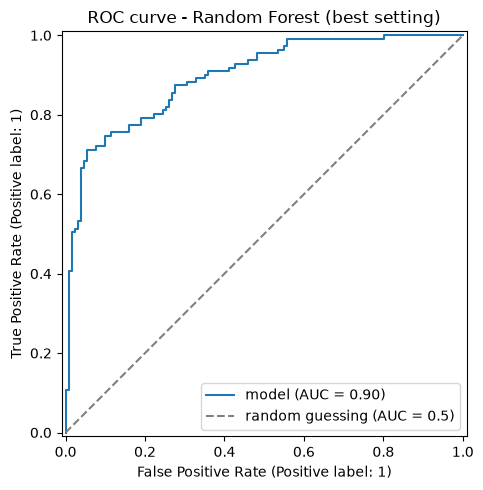

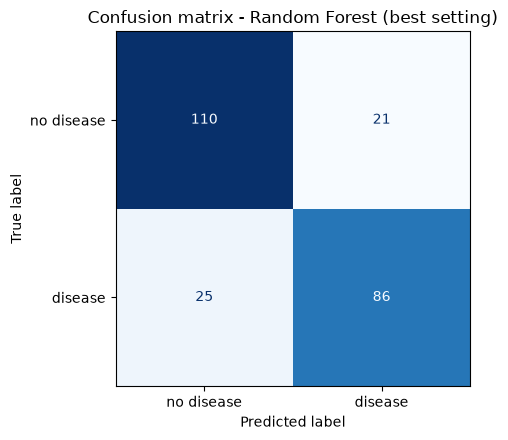

In [16]:
# plots for the best setting, from the cross-validation predictions
best_pipeline = clone(pipeline).set_params(**search.best_params_)
probability = cross_val_probabilities(best_pipeline, X_train, y_train, folds)

plot_roc_curve(y_train, probability, f"ROC curve - {model_name} (best setting)")
plot_confusion_matrix(y_train, probability, f"Confusion matrix - {model_name} (best setting)")
plt.show()

Observations

The best setting is `max_depth` = 5, `min_samples_leaf` = 3 and 300 trees, with
a mean ROC-AUC of 0.905. Tuning gave a small gain for this model. The fully
grown trees (no depth limit, 1 patient in a leaf), which include the default
setting, have the lowest ROC-AUC of all (0.889 and 0.888).

- Once the size of the trees is limited, the exact values matter little. All
  the other settings are between 0.894 and 0.905.
- The gain from 300 trees over 100 is small, 0.008 at most, and in two pairs
  100 trees are slightly higher.

Recall is 0.774 at the best setting, so about 23% of the patients with disease
are missed.

## 7. Gradient Boosting

Decision trees built one after another, each correcting the errors left by the
earlier ones. The depth of the trees (`max_depth`), the number of trees
(`n_estimators`) and the learning rate (`learning_rate`) are tuned. The
default setting (learning rate 0.1, depth 3, 100 trees) is one of the
combinations tried.

In [17]:
model_name = "Gradient Boosting"

model, grid = MODELS[model_name]
pipeline = make_pipeline(model)

# each setting is written from the simplest value to the most complex
for setting, values in grid.items():
    print(setting, "=", values)

model__learning_rate = [0.05, 0.1]
model__max_depth = [1, 2, 3]
model__n_estimators = [50, 100, 200]


In [18]:
search = run_grid_search(pipeline, grid, X_train, y_train, folds)
metrics_table = build_metrics_table(search)

print("Combinations tried:", len(metrics_table))
print("Best setting by ROC-AUC:", search.best_params_)

Combinations tried: 18
Best setting by ROC-AUC: {'model__learning_rate': 0.1, 'model__max_depth': 1, 'model__n_estimators': 50}


In [19]:
# recorded in MLflow: a parent run for the model, a child run for each
# combination, and the trained model of the best setting
log_model_runs(model_name, pipeline, search, metrics_table, X_train, y_train, folds)

Logged to MLflow: Gradient Boosting, 18 combinations.


In [20]:
# mean ± std over the 10 folds
readable_metrics(metrics_table)

,learning_rate,max_depth,n_estimators,accuracy,precision,recall,f1,roc_auc
0,0.05,1,50,0.835 ± 0.042,0.886 ± 0.103,0.757 ± 0.108,0.806 ± 0.055,0.890 ± 0.043
1,0.05,1,100,0.831 ± 0.034,0.873 ± 0.092,0.757 ± 0.091,0.803 ± 0.040,0.897 ± 0.040
2,0.05,1,200,0.814 ± 0.034,0.826 ± 0.083,0.775 ± 0.092,0.792 ± 0.038,0.890 ± 0.042
3,0.05,2,50,0.822 ± 0.057,0.845 ± 0.106,0.775 ± 0.109,0.799 ± 0.061,0.888 ± 0.046
4,0.05,2,100,0.798 ± 0.056,0.802 ± 0.094,0.767 ± 0.127,0.774 ± 0.065,0.886 ± 0.046
5,0.05,2,200,0.781 ± 0.057,0.796 ± 0.119,0.739 ± 0.101,0.756 ± 0.056,0.880 ± 0.049
6,0.05,3,50,0.785 ± 0.061,0.816 ± 0.119,0.721 ± 0.083,0.757 ± 0.055,0.875 ± 0.048
7,0.05,3,100,0.777 ± 0.056,0.778 ± 0.072,0.730 ± 0.105,0.748 ± 0.065,0.873 ± 0.056
8,0.05,3,200,0.777 ± 0.060,0.772 ± 0.082,0.748 ± 0.098,0.754 ± 0.063,0.861 ± 0.062
9,0.10,1,50,0.831 ± 0.043,0.866 ± 0.100,0.766 ± 0.083,0.806 ± 0.046,0.899 ± 0.038


In [21]:
# default setting (learning rate 0.1, depth 3, 100 trees) against the best
# setting
default_row = metrics_table[
    (metrics_table["learning_rate"] == 0.1)
    & (metrics_table["max_depth"] == 3)
    & (metrics_table["n_estimators"] == 100)
]
best_row = metrics_table.loc[[search.best_index_]]

comparison = pd.concat([default_row, best_row])
comparison.insert(0, "setting", ["default", "best"])
readable_metrics(comparison)

,setting,learning_rate,max_depth,n_estimators,accuracy,precision,recall,f1,roc_auc
16,default,0.1,3,100,0.777 ± 0.057,0.776 ± 0.079,0.739 ± 0.086,0.752 ± 0.058,0.860 ± 0.057
9,best,0.1,1,50,0.831 ± 0.043,0.866 ± 0.100,0.766 ± 0.083,0.806 ± 0.046,0.899 ± 0.038


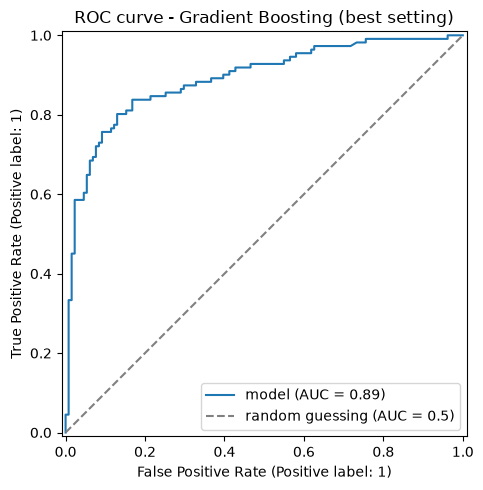

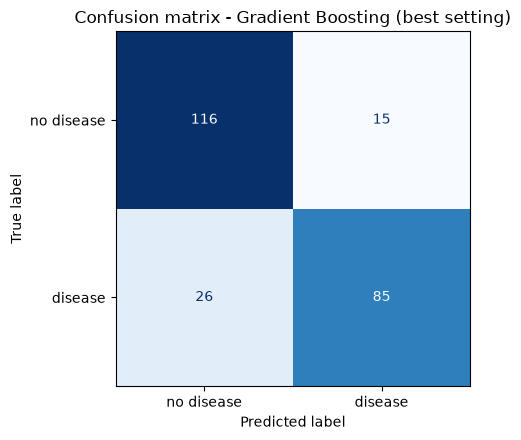

In [22]:
# plots for the best setting, from the cross-validation predictions
best_pipeline = clone(pipeline).set_params(**search.best_params_)
probability = cross_val_probabilities(best_pipeline, X_train, y_train, folds)

plot_roc_curve(y_train, probability, f"ROC curve - {model_name} (best setting)")
plot_confusion_matrix(y_train, probability, f"Confusion matrix - {model_name} (best setting)")
plt.show()

Observations

- The best setting is a learning rate of 0.1, `max_depth` = 1 and 50 trees,
  with a mean ROC-AUC of 0.899.
- The simpler settings do better. The highest ROC-AUC is 0.899 at depth 1,
  0.889 at depth 2 and 0.875 at depth 3.
- More trees do not help. At a learning rate of 0.1, ROC-AUC falls from 50 to
  200 trees at every depth.

Tuning mattered more for this model than for the other two. The default
setting has a ROC-AUC of 0.860, against 0.899 for the best setting. Recall is
0.766 at the best setting, so about 23% of the patients with disease are
missed.

## 8. XGBoost

The same method as Gradient Boosting, from the `xgboost` library. The same
values of `learning_rate`, `max_depth` and `n_estimators` are tried as in
section 7, so that the two can be compared. The default setting of XGBoost
(learning rate 0.3, depth 6, 100 trees) is added as one more combination.

In [23]:
model_name = "XGBoost"

model, grid = MODELS[model_name]
pipeline = make_pipeline(model)

# the grid has two parts
labels = ["Same values as for Gradient Boosting:", "Default setting of XGBoost:"]
for label, part in zip(labels, grid):
    print(label)
    for setting, values in part.items():
        print("  ", setting, "=", values)

Same values as for Gradient Boosting:
   model__learning_rate = [0.05, 0.1]
   model__max_depth = [1, 2, 3]
   model__n_estimators = [50, 100, 200]
Default setting of XGBoost:
   model__learning_rate = [0.3]
   model__max_depth = [6]
   model__n_estimators = [100]


In [24]:
search = run_grid_search(pipeline, grid, X_train, y_train, folds)
metrics_table = build_metrics_table(search)

print("Combinations tried:", len(metrics_table))
print("Best setting by ROC-AUC:", search.best_params_)

Combinations tried: 19
Best setting by ROC-AUC: {'model__learning_rate': 0.05, 'model__max_depth': 2, 'model__n_estimators': 100}


In [25]:
# recorded in MLflow: a parent run for the model, a child run for each
# combination, and the trained model of the best setting
log_model_runs(model_name, pipeline, search, metrics_table, X_train, y_train, folds)

Logged to MLflow: XGBoost, 19 combinations.


In [26]:
# mean ± std over the 10 folds
readable_metrics(metrics_table)

,learning_rate,max_depth,n_estimators,accuracy,precision,recall,f1,roc_auc
0,0.05,1,50,0.835 ± 0.042,0.886 ± 0.103,0.757 ± 0.108,0.806 ± 0.055,0.893 ± 0.042
1,0.05,1,100,0.831 ± 0.034,0.873 ± 0.092,0.757 ± 0.091,0.803 ± 0.040,0.898 ± 0.041
2,0.05,1,200,0.814 ± 0.042,0.827 ± 0.090,0.775 ± 0.092,0.792 ± 0.045,0.894 ± 0.042
3,0.05,2,50,0.806 ± 0.056,0.822 ± 0.113,0.767 ± 0.113,0.783 ± 0.061,0.896 ± 0.040
4,0.05,2,100,0.797 ± 0.065,0.807 ± 0.101,0.758 ± 0.120,0.773 ± 0.071,0.903 ± 0.039
5,0.05,2,200,0.785 ± 0.062,0.786 ± 0.086,0.748 ± 0.125,0.759 ± 0.071,0.883 ± 0.052
6,0.05,3,50,0.806 ± 0.059,0.824 ± 0.098,0.758 ± 0.120,0.780 ± 0.065,0.881 ± 0.042
7,0.05,3,100,0.802 ± 0.048,0.813 ± 0.062,0.748 ± 0.103,0.774 ± 0.057,0.873 ± 0.048
8,0.05,3,200,0.781 ± 0.066,0.788 ± 0.080,0.730 ± 0.120,0.751 ± 0.076,0.863 ± 0.059
9,0.10,1,50,0.831 ± 0.034,0.873 ± 0.092,0.757 ± 0.091,0.803 ± 0.040,0.900 ± 0.039


In [27]:
# default setting (learning rate 0.3, depth 6, 100 trees) against the best
# setting
default_row = metrics_table[
    (metrics_table["learning_rate"] == 0.3)
    & (metrics_table["max_depth"] == 6)
    & (metrics_table["n_estimators"] == 100)
]
best_row = metrics_table.loc[[search.best_index_]]

comparison = pd.concat([default_row, best_row])
comparison.insert(0, "setting", ["default", "best"])
readable_metrics(comparison)

,setting,learning_rate,max_depth,n_estimators,accuracy,precision,recall,f1,roc_auc
18,default,0.30,6,100,0.777 ± 0.083,0.780 ± 0.114,0.748 ± 0.089,0.757 ± 0.075,0.851 ± 0.054
4,best,0.05,2,100,0.797 ± 0.065,0.807 ± 0.101,0.758 ± 0.120,0.773 ± 0.071,0.903 ± 0.039


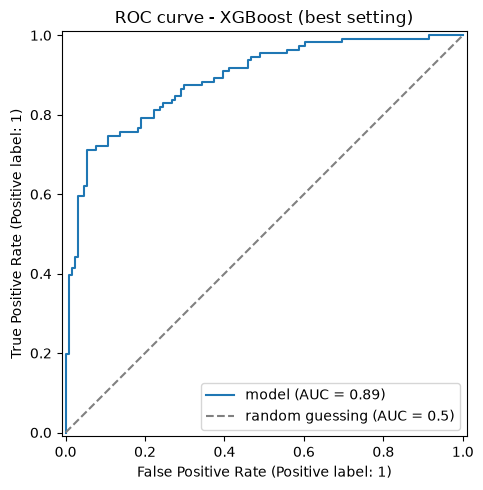

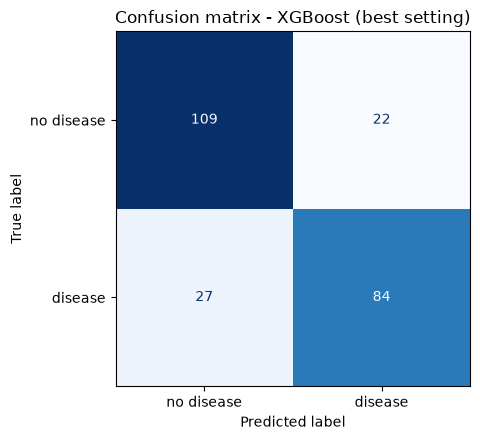

In [28]:
# plots for the best setting, from the cross-validation predictions
best_pipeline = clone(pipeline).set_params(**search.best_params_)
probability = cross_val_probabilities(best_pipeline, X_train, y_train, folds)

plot_roc_curve(y_train, probability, f"ROC curve - {model_name} (best setting)")
plot_confusion_matrix(y_train, probability, f"Confusion matrix - {model_name} (best setting)")
plt.show()

Observations

XGBoost behaves like Gradient Boosting on this data. Small trees do better:
the highest ROC-AUC is 0.900 at depth 1 and 0.903 at depth 2, against 0.881 at
depth 3. The default setting, with trees of depth 6, gives 0.851.

- The best setting is a learning rate of 0.05, `max_depth` = 2 and 100 trees,
  with a mean ROC-AUC of 0.903.
- This is 0.004 above the best of Gradient Boosting (0.899), which is not a
  real difference.
- Recall is 0.758 at the best setting, so about 24% of the patients with
  disease are missed.

## 9. Comparison of the models

The best setting of each model and its cross-validation metrics are read back
from the parent runs in MLflow.

In [29]:
results = load_model_results()
readable_metrics(results.drop(columns="run_id"))

,model,best_setting,accuracy,precision,recall,f1,roc_auc
0,Logistic Regression,C=0.1,0.831 ± 0.050,0.852 ± 0.097,0.784 ± 0.092,0.810 ± 0.049,0.905 ± 0.048
1,Random Forest,"max_depth=5, min_samples_leaf=3, n_estimators=300",0.810 ± 0.050,0.829 ± 0.115,0.774 ± 0.110,0.788 ± 0.048,0.905 ± 0.040
2,Gradient Boosting,"learning_rate=0.1, max_depth=1, n_estimators=50",0.831 ± 0.043,0.866 ± 0.100,0.766 ± 0.083,0.806 ± 0.046,0.899 ± 0.038
3,XGBoost,"learning_rate=0.05, max_depth=2, n_estimators=100",0.797 ± 0.065,0.807 ± 0.101,0.758 ± 0.120,0.773 ± 0.071,0.903 ± 0.039


Observations

The four models are close. The mean ROC-AUC is between 0.899 and 0.905, a gap
of 0.006, while the standard deviation across the folds is about 0.04. The
three tree-based models did not do better than the reference model.

Logistic Regression has the highest recall (0.784) and XGBoost the lowest
(0.758).

## 10. Selected model

The model is selected by a rule that was fixed before the test set was used:

- Models within 0.01 of the best mean ROC-AUC (one percentage point) are
  treated as close.
- Among the close models, the one with the highest mean recall is selected.

The rule is the function `select_best_model` in `src/evaluation.py`.

In [30]:
selected = select_best_model(results)

# the two numbers used by the rule, for each model
best_roc_auc = results["roc_auc_mean"].max()
check = results[["model", "roc_auc_mean", "recall_mean"]].round(3)
check["close to the best"] = results["roc_auc_mean"] >= best_roc_auc - ROC_AUC_GAP

print("Selected model:", selected["model"], "with", selected["best_setting"])
check

Selected model: Logistic Regression with C=0.1


,model,roc_auc_mean,recall_mean,close to the best
0,Logistic Regression,0.905,0.784,True
1,Random Forest,0.905,0.774,True
2,Gradient Boosting,0.899,0.766,True
3,XGBoost,0.903,0.758,True


All four models are within 0.01 of the best ROC-AUC, so recall decides.
Logistic Regression has the highest recall (0.784) and is the selected model.
It is also the simplest of the four models and the easiest to explain.

## 11. Evaluation on the test set

The selected model is evaluated on the 61 test patients. These patients were
not used for tuning or for selecting the model. Only the selected model is
evaluated on them, and only here.

A quality gate was fixed before this evaluation: the ROC-AUC on the test set
must be at least 0.80 (`ROC_AUC_GATE` in `src/evaluation.py`). It is a lower
limit to catch a faulty model, and not a target. It is kept below the
cross-validation value of about 0.90, because a result on 61 patients can
vary by chance.

In [31]:
# the model saved in the MLflow run of the selected model, trained on all
# the training patients
model = load_trained_model(selected["run_id"])

test_probability = model.predict_proba(X_test)[:, 1]
test_metrics = compute_metrics(y_test, test_probability)

# next to the cross-validation values of the same model
rows = []
for metric in METRICS:
    mean = selected[f"{metric}_mean"]
    std = selected[f"{metric}_std"]
    rows.append({
        "metric": metric,
        "cross-validation": f"{mean:.3f} ± {std:.3f}",
        "test set": f"{test_metrics[metric]:.3f}",
    })
pd.DataFrame(rows).set_index("metric")

,cross-validation,test set
metric,,
accuracy,0.831 ± 0.050,0.885
precision,0.852 ± 0.097,0.839
recall,0.784 ± 0.092,0.929
f1,0.810 ± 0.049,0.881
roc_auc,0.905 ± 0.048,0.965


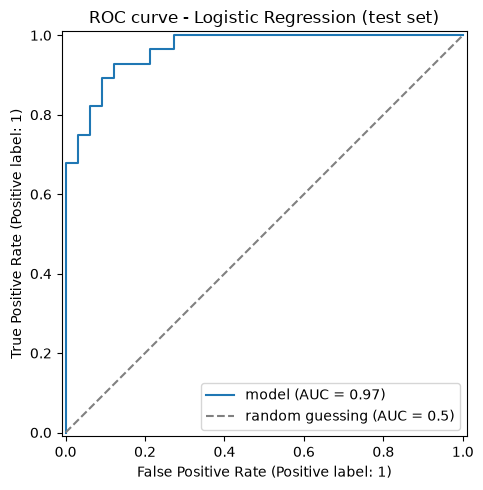

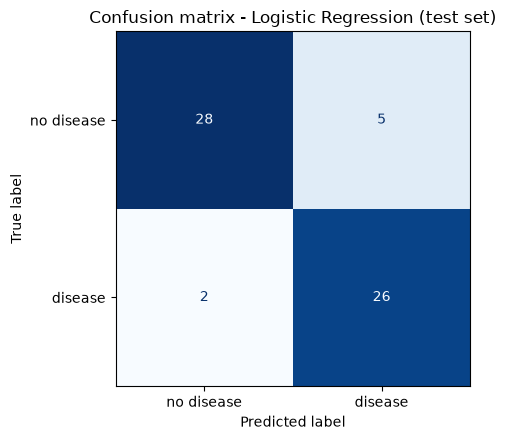

In [32]:
plot_roc_curve(y_test, test_probability, f"ROC curve - {selected['model']} (test set)")
plot_confusion_matrix(y_test, test_probability, f"Confusion matrix - {selected['model']} (test set)")
plt.show()

In [33]:
print("ROC-AUC on the test set:", round(test_metrics["roc_auc"], 3))
print("Quality gate:", ROC_AUC_GATE)
print("Gate passed:", passes_quality_gate(test_metrics))

ROC-AUC on the test set: 0.965
Quality gate: 0.8
Gate passed: True


In [34]:
# the test metrics and plots are added to the MLflow run of the selected model
log_test_results(selected["run_id"], selected["model"], test_metrics, y_test, test_probability)

Logged to MLflow: test results of Logistic Regression.


Observations

The quality gate is passed. The ROC-AUC on the test set is 0.965, against the
limit of 0.80.

- All the test metrics except precision are higher than the cross-validation
  means. ROC-AUC is 0.965 against 0.905, and recall is 0.929 against 0.784.
- Of the 28 test patients with disease, 26 are found and 2 are missed. Of the
  33 without disease, 5 are predicted as having the disease.
- The test results are not lower than the cross-validation results, so there
  is no sign of overfitting.

The test set has only 61 patients, and 28 of them have the disease, so one
patient changes recall by about 0.036. The higher values on the test set are
therefore not taken as the real level of the model. The cross-validation
means, which come from 242 patients, remain the more reliable estimate.

## Viewing the runs in MLflow

```
mlflow ui --backend-store-uri sqlite:///mlflow.db --port 5000
```